# Рассылка приносит дополнительные покупки или получает органическую выручку?

Реальный рандомизированный эксперимент [Hillstrom / MineThatData](https://blog.minethatdata.com/2008/03/minethatdata-e-mail-analytics-and-data.html): покупатели, письмо и контроль, двухнедельное окно. Методика подходит для задач CRM продуктовой команды. Это повторный анализ исторического эксперимента.

## 1. Продуктовый вопрос и план

Основная метрика — **выручка на каждого назначенного участника за 14 дней**, включая нулевые траты. Основная проверка — двусторонний Welch, alpha = 5%.

Сравнение `Mens E-Mail` и `No E-Mail` выбрано заранее. `Mens` обозначает коллекцию в письме, а не пол покупателя. Группы не пересоздаются. [План анализа](docs/design.md) сохранён до просмотра результатов; исходный эксперимент уже был проведён автором в 2008 году.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, Markdown, display
from ab_test import load_data, select_ab, welch_effect, hash_group

ROOT = Path.cwd()
frame, source = load_data(ROOT)
ab = select_ab(frame)
print('Строк в источнике:', len(frame), '; в выбранном A/B:', len(ab))
print('SHA-256:', source['sha256'])
assert (ab.treatment.eq(1) == ab.segment.eq('Mens E-Mail')).all()
display(frame.segment.value_counts().to_frame('Участников исходного эксперимента'))

Строк в источнике: 64000 ; в выбранном A/B: 42613
SHA-256: 0e5893329d8b93cefecc571777672028290ab69865718020c78c7284f291aece


,Участников исходного эксперимента
segment,
Womens E-Mail,21387
Mens E-Mail,21307
No E-Mail,21306


## 2. Метрика и единица анализа

Одна строка — один покупатель по описанию автора. Считаем всех назначенных: исключение некупивших поменяло бы вопрос и создало отбор по результату воздействия. `record_id` — технический номер строки фиксированного CSV, не реальный пользовательский идентификатор. Одинаковые признаки разных строк автоматически не удаляются.

,group,original_segment,n,buyers,revenue_per_customer,conversion_rate,visit_rate,zero_spend_share
0,A,No E-Mail,21306,122,0.652789,0.005726,0.106167,0.994274
1,B,Mens E-Mail,21307,267,1.422617,0.012531,0.182757,0.987469


Проверки качества: {'srm_pvalue': 0.9961348415003554, 'exact_feature_duplicates': 6562, 'spend_conversion_mismatches': 0, 'original_assignment_preserved': True}


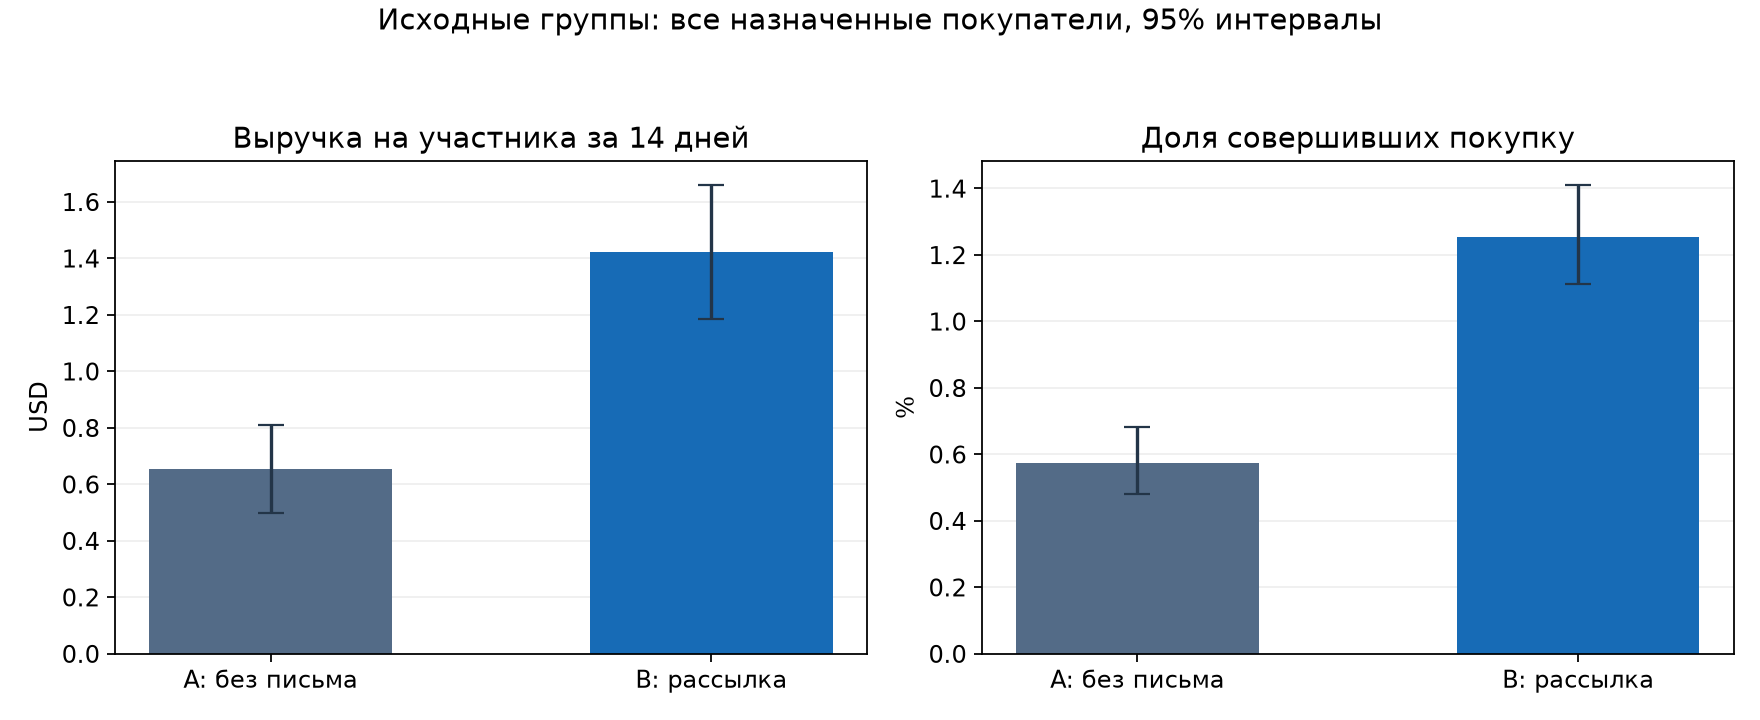

In [2]:
summary = pd.read_csv(ROOT / 'results/group_metrics.csv')
analysis = json.loads((ROOT / 'results/analysis.json').read_text(encoding='utf-8'))
display(summary[['group', 'original_segment', 'n', 'buyers', 'revenue_per_customer', 'conversion_rate', 'visit_rate', 'zero_spend_share']])
print('Проверки качества:', analysis['checks'])
display(Image(filename=str(ROOT / 'results/group_metrics.png')))

## 3. Планируем аналогичный будущий эксперимент

H0: средняя выручка B − A = 0. MDE = 0,50 USD, SD = 15 USD, alpha = 5%, power = 80%, 50/50. Это условные допущения, зафиксированные до анализа; они не выданы за реальные исторические параметры.

Размер выборки показывает потребность в участниках. Длительность набора требует прогноза трафика; после набора последнего участника нужны полные 14 дней. По результату исторического теста «наблюдаемая мощность» не рассчитывается.

Покупателей на группу: 14129
Всего: 28258
Пример для конверсии 1% → 1,3%: {'assumed_baseline': 0.01, 'mde_pp': 0.3, 'n_per_arm': 19744}


,mde_usd,assumed_sd_usd,n_per_arm
0,0.25,10.0,25118
1,0.50,10.0,6281
2,1.00,10.0,1571
3,0.25,15.0,56513
4,0.50,15.0,14129
5,1.00,15.0,3533
6,0.25,20.0,100467
7,0.50,20.0,25118
8,1.00,20.0,6281


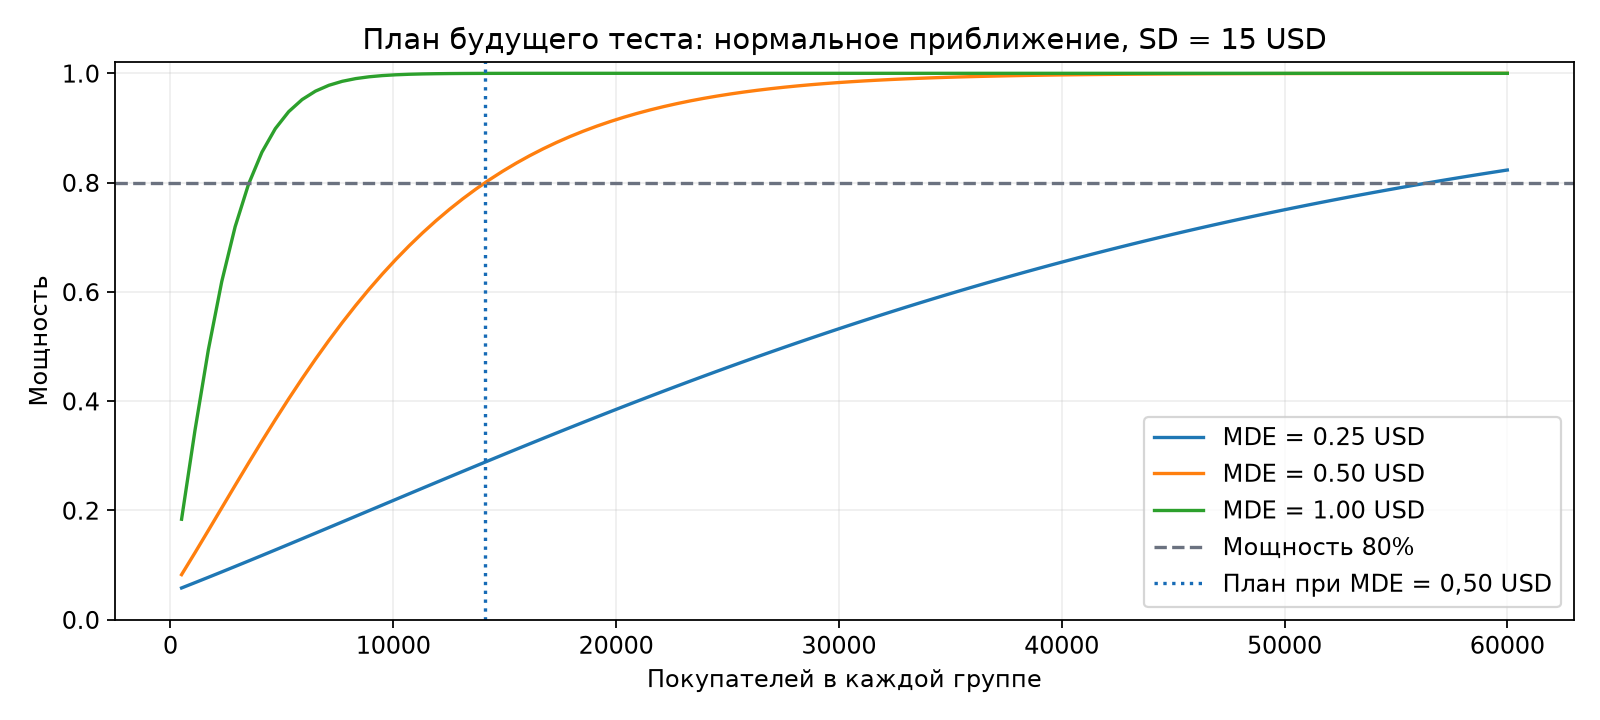

In [3]:
plan = json.loads((ROOT / 'results/sample_size.json').read_text(encoding='utf-8'))
print('Покупателей на группу:', plan['n_per_arm_primary'])
print('Всего:', plan['n_total_primary'])
print('Пример для конверсии 1% → 1,3%:', plan['conversion_example'])
display(pd.read_csv(ROOT / 'results/sample_size_sensitivity.csv'))
display(Image(filename=str(ROOT / 'results/power_curve.png')))

## 4. Диагностика назначения

SRM проверяет размеры групп против ожидаемого 1:1; порог диагностики = 0,001. Баланс `history`, `recency` и других признаков до письма показываем через standardized mean difference. Отсутствие SRM не доказывает корректность исходной системы назначения.

In [4]:
print('SRM p-value:', analysis['checks']['srm_pvalue'])
display(pd.read_csv(ROOT / 'results/pre_experiment_balance.csv'))
print('Демонстрация SHA-256 с солью; этот сплит НЕ заменяет исходные группы:')
display(pd.DataFrame({'Технический ID': range(5), 'Учебная группа': [hash_group(i, 'example-v1') for i in range(5)]}))

SRM p-value: 0.9961348415003554


,pre_experiment_feature,mean_a,mean_b,standardized_mean_difference
0,history,240.882653,242.835931,0.007613
1,recency,5.749695,5.773642,0.006832
2,mens,0.553224,0.550946,-0.004582
3,womens,0.547639,0.551415,0.007589
4,newbie,0.501971,0.501525,-0.000892


Демонстрация SHA-256 с солью; этот сплит НЕ заменяет исходные группы:


,Технический ID,Учебная группа
0,0,A
1,1,A
2,2,B
3,3,A
4,4,A


## 5. Welch, Mann–Whitney и bootstrap

**Welch** отвечает на основной вопрос о разнице средних. **Mann–Whitney** проверяет ранговое различие распределений; без дополнительных условий он не является тестом средней выручки или медиан. Много совпадающих нулей учитывается асимптотической поправкой.

**Bootstrap** перевыбирает целых покупателей отдельно внутри каждой группы. Три подхода не используются для поиска удобного p-value; решение заранее привязано к Welch. Конверсия и визиты — вторичные описательные метрики без самостоятельного решения по значимости.

In [5]:
a = ab.loc[ab.group.eq('A'), 'spend']
b = ab.loc[ab.group.eq('B'), 'spend']
calculated = welch_effect(b, a)
assert abs(calculated['effect'] - analysis['welch']['effect']) < 1e-10
print('Welch:', analysis['welch'])
print('Mann–Whitney:', analysis['mann_whitney'])
print('Bootstrap 95% CI разницы средних:', analysis['bootstrap_ci'])

Welch: {'effect': 0.7698271558945368, 'ci_low': 0.4851397325684076, 'ci_high': 1.0545145792206658, 'pvalue': 1.1638149682254818e-07, 'se': 0.14524656024868676}
Mann–Whitney: {'u_statistic': 228527081.0, 'pvalue': 1.5819988266809648e-13, 'probability_superiority': 0.503400269616989}
Bootstrap 95% CI разницы средних: [0.49926827360096626, 1.049974038027531]


## 6. CUPED: можно ли убрать часть шума?

`history` содержит траты за год **до** рассылки. Оцениваем общую линейную зависимость от этой предыстории: `Y_adj = Y − theta × (history − mean(history))`. Коэффициент treatment в регрессии `spend ~ treatment + centered_history` даёт разницу скорректированных средних; HC3 учитывает неодинаковую дисперсию и оценку коэффициентов.

`visit`, `conversion` и текущий `spend` нельзя подставлять как ковариаты: они измерены после воздействия. CUPED здесь — анализ чувствительности; исходный Welch не заменяется после просмотра результата.

,Метод,effect,ci_low,ci_high,pvalue,se,theta,covariate,variance_reduction_pct,history_outcome_correlation
0,Welch,0.769827,0.485140,1.054515,1.163815e-07,0.145247,NaN,NaN,NaN,NaN
1,CUPED / ANCOVA HC3,0.767450,0.482951,1.051948,1.247795e-07,0.145151,0.001217,history,0.043397,0.020923


Уменьшение внутригрупповой дисперсии, %: 0.043396634158443526


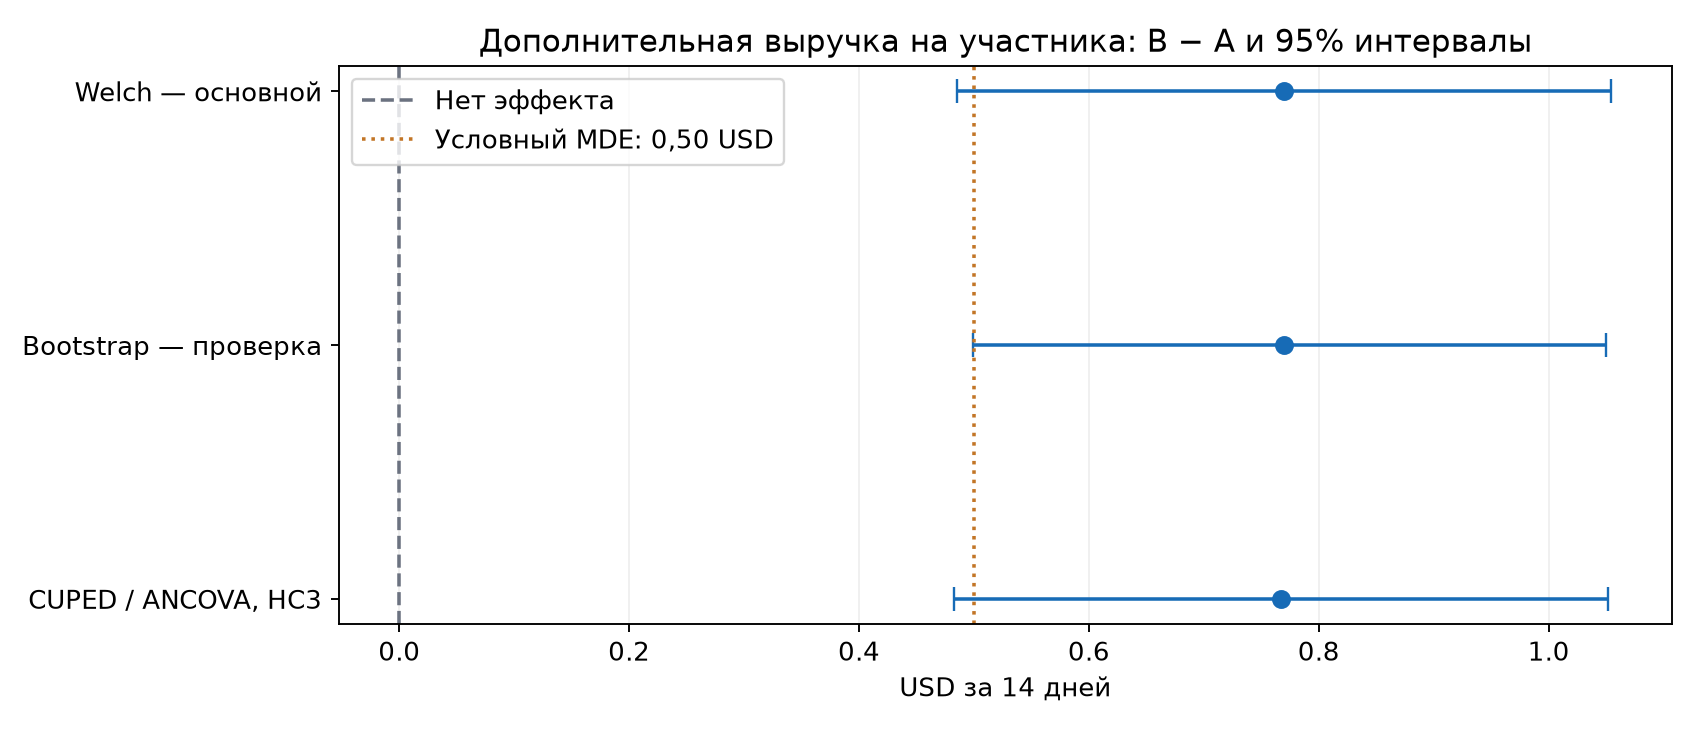

In [6]:
cuped = analysis['cuped']
display(pd.DataFrame([{'Метод': name, **analysis[key]} for name, key in [('Welch', 'welch'), ('CUPED / ANCOVA HC3', 'cuped')]]))
print('Уменьшение внутригрупповой дисперсии, %:', cuped['variance_reduction_pct'])
display(Image(filename=str(ROOT / 'results/effect_intervals.png')))

## 7. Учебный A/A

Используем только исходную группу без письма. Один пример назначается стабильным хэшем с фиксированной солью, затем 500 случайных разбиений дают эмпирическую частоту p-value < 0,05. Публикуются все повторы; соль и seed не подбираются.

Это офлайн-диагностика расчёта, а не live A/A и не доказательство корректности реального назначения. Отдельный значимый A/A возможен случайно; p > 0,05 не доказывает эквивалентности групп.

Хэш-сплит: 10545 10761 ; p-value: 0.08251256836726457
Повторов: 500 ; ложных срабатываний: 27
Частота: 0.054 ; 95% CI: 0.03737435018105752 0.0774265615106471


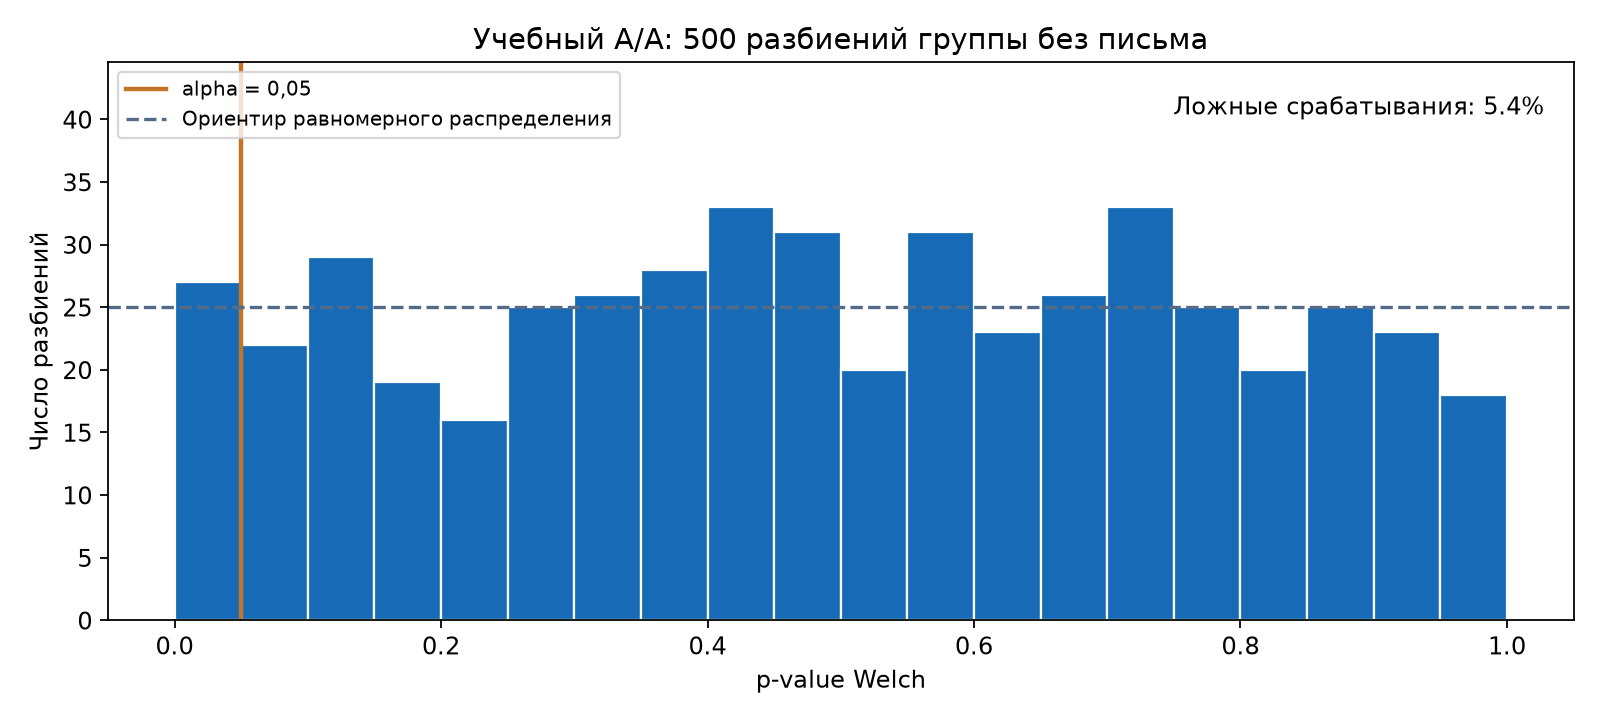

In [7]:
aa = json.loads((ROOT / 'results/aa_summary.json').read_text(encoding='utf-8'))
print('Хэш-сплит:', aa['demo_a'], aa['demo_b'], '; p-value:', aa['demo']['pvalue'])
print('Повторов:', aa['repetitions'], '; ложных срабатываний:', aa['rejected'])
print('Частота:', aa['rejection_rate'], '; 95% CI:', aa['rejection_rate_ci_low'], aa['rejection_rate_ci_high'])
display(Image(filename=str(ROOT / 'results/aa_calibration.png')))

## 8. Что решаем по результатам

Отделяем статистическое свидетельство эффекта от превышения условного бизнес-порога и прибыльности. Если 95% интервал включает эффект меньше 0,50 USD, достижение MDE не доказано. Стоимость контакта, маржа, жалобы, отписки и долгосрочное удержание отсутствуют.

In [8]:
report = (ROOT / 'results/report.md').read_text(encoding='utf-8')
display(Markdown(report.split('## Решение', 1)[1].split('## Данные и группы', 1)[0]))



По основной метрике есть статистические свидетельства роста выручки от рассылки. Прибыльность и допустимость масштабирования требуют данных о затратах, марже и негативной реакции клиентов.

Выручка на назначенного покупателя выросла на **0.770 USD** (+117.9% к контролю); 95% CI **[0.485; 1.055] USD**, Welch p-value = **1.1638e-07**. Это эффект письма с товарами мужской коллекции против отсутствия письма за 14 дней в историческом эксперименте, без переноса на другую аудиторию.

95% интервал включает эффекты ниже условного MDE: превышение бизнес-порога не установлено, даже если точечная оценка больше него.



## 9. Вопросы для собеседования

- Почему нельзя сравнивать только средние чеки совершивших покупку?
- Чем отличается рост выручки получателей от инкрементального эффекта?
- Зачем различать статистическую значимость и MDE?
- Почему Mann–Whitney нельзя автоматически назвать проверкой средней выручки?
- Когда CUPED помогает и откуда должна браться ковариата?
- Чем офлайн A/A отличается от реального эксперимента на продукте?

[Полный отчёт и формулировка для анкеты](results/report.md).